# CSCI6032 Homework 7

**Instructions**

* **Insert all code, plots, results, and discussion** into this Jupyter Notebook.
* Your homework should be submitted as a **single Jupyter Notebook** (.ipynb file) to **Blackboard**.
* While working, you can use Visual Studio Code, Jupyter Notebook or Google Colab.  If using Google Colab, export it as a Jupyter Notebook (.ipynb).

You can answer mathematical questions either by:
* using LaTeX in a markdown cell, or
* handwriting your answer, then photographing or scanning it and using an AI/LLM to convert it into markdown and LaTeX, checking the conversion for accuracy before submitting.


---
## Problem 1: Logistic Regression, Compared with GDA and QDA

Implement logistic regression using only numpy and standard python libraries (pandas may be used to load the data and
matplotlib to plot it).  No usage of any existing implementation of logistic regression is allowed.

Logistic regression models the posterior probability directly,
$P(y=1 \mid \bar x)=\sigma(\bar w^T\bar x+b)$ with $\sigma(z)=1/(1+e^{-z})$, and learns $\bar w$ and $b$ by minimizing the
cross-entropy loss, for example by gradient descent.

Write your implementation so that it works on a whole batch of samples at once: a method that computes
$\hat{\bar y} = \sigma(X\bar w + b)$ for all rows of a data matrix $X$, and a method that computes the gradient of the average
cross-entropy loss.  You will derive this gradient in Problem 4.

This problem uses the data set and the training/test split from Homework 5.

**(a)** Apply the unit test from HW5 Problem 6(b) to the data set you created in HW5 Problem 6(a).  Confirm that logistic
regression achieves 100% accuracy on it. (4 points)

**(b)** Open the provided file `p6_data.csv`.  It is the same file as in HW5 Problem 6(c).  Use the **same training/test split** you
used in HW5, so that the comparison with GDA below is fair.  Train a model using your implementation of logistic regression. (6 points)

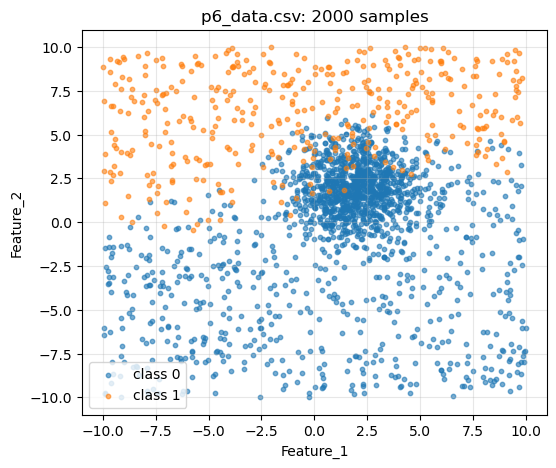

,Feature_1,Feature_2,Label
0,0.427171,-0.130027,0
1,4.646079,2.600236,0
2,1.256307,3.824867,0
3,5.175187,-0.416318,0
4,0.903690,-0.462555,0
...,...,...,...
1995,-6.536135,7.503992,1
1996,-9.446937,3.206772,1
1997,-1.711223,5.825631,1
1998,4.423962,-0.397844,0


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
data = pd.read_csv('p6_data.csv')

# Extract features and target variable from the dataset
X = data[['Feature_1', 'Feature_2']]  # the feature columns
y = data['Label']  # the target column

# Plot the data, one color per class
plt.figure(figsize=(6, 5))
for label, color in ((0, 'tab:blue'), (1, 'tab:orange')):
    points = data[data['Label'] == label]
    plt.scatter(points['Feature_1'], points['Feature_2'], s=10, alpha=0.6, color=color, label=f'class {label}')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.title('p6_data.csv: %d samples' % len(data))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

data


**(c)** Output the data labelling each sample according to its class, and color the background in each area according to
which side of the decision boundary the area resides. (4 points)

**(d)** Output the model parameters and the error rate on the test set, i.e., 1-accuracy. (2 points)

**(e)** Start from your GDA implementation from HW5 Problem 6(d) and turn it into **QDA** by giving each class its own covariance
matrix, $\Sigma_0$ and $\Sigma_1$, instead of one shared $\Sigma$.  Train it on the same training set.  Output the same things as in
(c) and (d); its parameters now include both covariance matrices. (7 points)

**(f)** Make a table of the test error rates of logistic regression, GDA (from HW5 Problem 6(f)), and QDA.  Which is lowest?  Is
the difference between them large compared with the sampling error of an error rate measured on a test set of this size?
(*Hint:* an error rate $e$ measured on $n$ test samples has a standard error of about $\sqrt{e(1-e)/n}$.) (4 points)

**(g)** If both classes are Gaussian with a shared covariance matrix, then $P(y=1 \mid \bar x)$ is a logistic function of a linear
function of $\bar x$, which is exactly the model logistic regression fits.  Why can GDA and logistic regression still produce
different decision boundaries on the same data? (6 points)

---
## Problem 2: Nearly Separable, but Not Linearly Separable

The file `p3_data.csv` has two features and a label, in the same format as `p6_data.csv`.

**(a)** The cell below loads the data and plots it, with one color per class.  Describe the shape of a boundary that would separate the
classes.  Could a straight line separate them well?  Are the classes completely separable by some boundary? (2 points)

**(b)** Divide the data into a training set and a test set.  Train your logistic regression from Problem 1.  Output the data
with the background colored by the decision regions, and the error rate on the test set. (4 points)

**(c)** Train your QDA from Problem 1(e) on the same training set and output the same things. (4 points)

**(d)** Both classifiers have a high error rate even though the classes are nearly separable.  Explain why.  What shapes of decision boundary can each
model represent, and what shape would this data need? (6 points)

**(e)** The boundary in this data oscillates like a sine wave, with exactly one period across the range $0 \le x_1 \le 6$.  Add two features to every
sample, $\sin(2\pi x_1/6)$ and $\cos(2\pi x_1/6)$, and train your logistic regression on all four features
$\big(x_1,\; x_2,\; \sin(2\pi x_1/6),\; \cos(2\pi x_1/6)\big)$.  Report the test error rate.  Why does adding these features help, and in what sense is the model
still a *linear* model? (6 points)

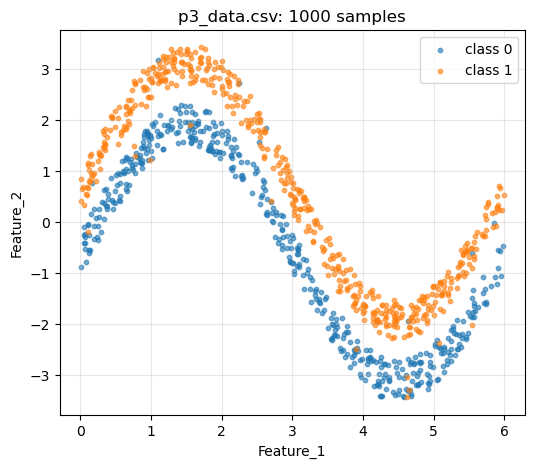

,Feature_1,Feature_2,Label
0,4.434914,-1.520642,1
1,3.920444,-2.465408,0
2,4.161380,-3.210213,0
3,4.217785,-1.458661,1
4,2.593371,1.261493,1
...,...,...,...
995,4.611392,-3.003120,0
996,3.522415,-0.319140,1
997,1.280947,3.386566,1
998,2.813997,-0.341852,0


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
data = pd.read_csv('p3_data.csv')

# Plot the data, one color per class
plt.figure(figsize=(6, 5))
for label, color in ((0, 'tab:blue'), (1, 'tab:orange')):
    points = data[data['Label'] == label]
    plt.scatter(points['Feature_1'], points['Feature_2'], s=10, alpha=0.6, color=color, label=f'class {label}')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.title('p3_data.csv: %d samples' % len(data))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

data


---
## Problem 3: Maximum Likelihood and Where Loss Functions Come From

In lectures 19 and 20 we derived logistic regression by maximum likelihood estimation (MLE).  This problem shows that the loss
functions we minimize are not arbitrary choices: each one is the negative log-likelihood of a model of how the labels were
generated.  Reading: Goodfellow, Bengio & Courville, *Deep Learning*, §5.5.

**(a) Coin flips.**  A coin lands heads with an unknown probability $p$.  In $n$ independent flips you observe $k$ heads.

1. Write the likelihood $L(p)$ of the observed flips.
2. Find the log-likelihood $\ell(p) = \log L(p)$, and show that the maximum likelihood estimate is $\hat p = k/n$.
3. Explain why maximizing $\ell(p)$ gives the same $p$ as maximizing $L(p)$.  Give an example of a transformation of $L$ that
   would *not* preserve the argmax, and use it to explain why machine learning minimizes the *negative* log-likelihood rather
   than maximizing the likelihood. (6 points)

**(b) Logistic regression's loss is a negative log-likelihood.**  Logistic regression models each label as a Bernoulli random
variable with $P(y=1 \mid \bar x) = \hat y = \sigma(\bar w^T\bar x + b)$.

1. Show that $P(y \mid \bar x) = \hat y^{\,y}(1-\hat y)^{1-y}$ for $y \in \{0, 1\}$.
2. Write the likelihood of the labels of a training set $\{(\bar x^{(i)}, y^{(i)})\}_{i=1}^m$, treating the $\bar x^{(i)}$ as fixed.
   Where does the assumption that the samples are independent enter?
3. Show that the negative log-likelihood, divided by $m$, is the cross-entropy loss
   $$J(\bar w, b) = -\frac{1}{m}\sum_{i=1}^m \Big[y^{(i)}\log \hat y^{(i)} + (1-y^{(i)})\log\big(1-\hat y^{(i)}\big)\Big]$$
   that you minimize in Problem 1. (6 points)

**(c) Gaussian noise gives squared error.**  Now suppose the target is real-valued, $y = \bar w^T\bar x + b + \epsilon$, where the
noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$ is independent for each sample and $\sigma$ is known.

1. Write $P(y \mid \bar x)$ and the likelihood of the training labels.
2. Show that maximizing the likelihood over $\bar w$ and $b$ is the same as minimizing $\sum_i \big(y^{(i)} - \hat y^{(i)}\big)^2$,
   where $\hat y = \bar w^T\bar x + b$.  This is the least-squares problem whose normal equation you found in Homework 3.
3. For a real-valued target and for a binary target, which output (linear or sigmoid) and which loss would you choose, and why? (5 points)

**(d) When the maximum likelihood estimate does not exist.**  The data set you created in HW5 Problem 6(a) is linearly separable,
which is why logistic regression reaches 100% accuracy on it in Problem 1(a).

1. Suppose $\bar w$ and $b$ classify every training sample correctly.  Show that the likelihood of $(c\,\bar w,\, c\,b)$ increases as
   $c$ increases, and approaches 1 as $c \to \infty$.  Conclude that no finite $\bar w, b$ maximizes the likelihood.
2. Train your logistic regression from Problem 1 on that data set, and plot $\|\bar w\|$ and the training loss against the
   iteration number (use a logarithmic axis for the iterations).  Does $\|\bar w\|$ settle to a value?
3. Why is 100% accuracy not a sign that anything is wrong here?  What does (1) suggest about how long to train, or about
   adding a penalty on $\|\bar w\|$ to the loss (regularization)? (7 points)

---
## Problem 4: The Gradient of Logistic Regression, Step by Step

In lecture we found the gradient of the log-likelihood one partial derivative at a time.  Here you derive it again by treating
logistic regression as a network with a single neuron: compute forward from the input to the loss, then apply the chain rule
backward.  Neural networks are built from many such neurons, and backpropagation applies these same steps to each of them.

For one sample $(\bar x, y)$ the computation is
$$\bar x \;\longrightarrow\; z = \bar w^T\bar x + b \;\longrightarrow\; \hat y = \sigma(z) \;\longrightarrow\;
L = -\big[y\log\hat y + (1-y)\log(1-\hat y)\big].$$

**(a) One neuron, forward and backward.**

1. Draw this computation as a graph, with one node per quantity ($\bar x$, $z$, $\hat y$, $L$) and an edge for each step.
2. Show that $\sigma'(z) = \sigma(z)\big(1-\sigma(z)\big)$.
3. Using the chain rule, $\frac{\partial L}{\partial z} = \frac{\partial L}{\partial \hat y}\,\frac{d\hat y}{dz}$, show that
   $\frac{\partial L}{\partial z} = \hat y - y$.
4. Show that $\frac{\partial L}{\partial \bar w} = (\hat y - y)\,\bar x$ and $\frac{\partial L}{\partial b} = \hat y - y$.
5. Compare your result with the gradient of the log-likelihood derived in lecture, $\frac{\partial \ell}{\partial \theta_j} =
   \sum_i \big(y^{(i)} - \sigma(\theta^T\bar x^{(i)})\big)x_j^{(i)}$.  Explain the difference in sign.
6. Write the stochastic gradient descent update rules for $\bar w$ and $b$.
7. For a batch of $m$ samples stacked as the rows of an $m \times n$ matrix $X$, with labels $\bar y$, show that the gradient of the
   average loss $J$ is $\nabla_{\bar w} J = \frac{1}{m}X^T(\hat{\bar y} - \bar y)$ and $\frac{\partial J}{\partial b} = \frac{1}{m}\sum_i
   \big(\hat y^{(i)} - y^{(i)}\big)$, where $\hat{\bar y} = \sigma(X\bar w + b)$.  Confirm that your Problem 1 implementation
   computes exactly this. (9 points)

**(b) Why cross-entropy rather than squared error?**  Replace the loss with $L_{sq} = \frac12(\hat y - y)^2$, keeping the sigmoid output.

1. Show that $\frac{\partial L_{sq}}{\partial z} = (\hat y - y)\,\hat y\,(1-\hat y)$.
2. Take $y = 1$ and $z = -6$, a confidently wrong prediction.  Compute $\frac{\partial L}{\partial z}$ for both losses.
3. Explain why gradient descent on squared error learns very slowly when the sigmoid saturates, and why cross-entropy does not
   have this problem.  (Reading: *Deep Learning* §6.2.2.2.) (5 points)

---
## Problem 5: The XOR Problem

The exclusive-or (XOR) function of two binary inputs is 1 when exactly one of them is 1.  The file `p4_data.csv` holds 400 noisy XOR samples: the points near
$(0,0)$ and $(1,1)$ are class 0, and the points near $(0,1)$ and $(1,0)$ are class 1.

**(a)** The cell below loads the data and plots it, with one color per class.  Divide the data into a training set and a test set. (2 points)

**(b)** Train your logistic regression from Problem 1 on the training set.  Report its test accuracy, plot its decision regions, and
report the loss it reaches on the training set and the range of the probabilities it predicts.  Compare that loss with $\ln 2 \approx 0.693$,
the loss of a model that always predicts $P(y=1)=0.5$.  **Explain how and why logistic regression fails on this data.** (5 points)

In lecture 21 we will see how a network with one hidden layer solves this problem, and in Homework 8 you will build and train one.

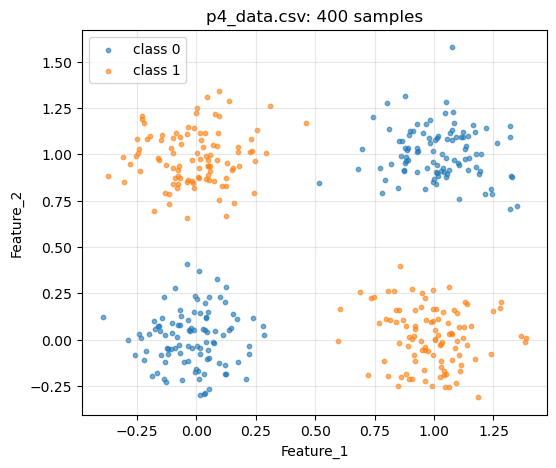

,Feature_1,Feature_2,Label
0,0.050774,0.937707,1
1,-0.067510,1.093427,1
2,0.921592,0.157351,1
3,1.004248,0.004463,1
4,0.851559,-0.018868,1
...,...,...,...
395,1.112094,1.091556,0
396,1.102293,0.953460,0
397,-0.172649,0.056355,0
398,-0.370747,0.880466,1


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
data = pd.read_csv('p4_data.csv')

# Plot the data, one color per class
plt.figure(figsize=(6, 5))
for label, color in ((0, 'tab:blue'), (1, 'tab:orange')):
    points = data[data['Label'] == label]
    plt.scatter(points['Feature_1'], points['Feature_2'], s=10, alpha=0.6, color=color, label=f'class {label}')
plt.xlabel('Feature_1')
plt.ylabel('Feature_2')
plt.title('p4_data.csv: %d samples' % len(data))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

data
